# Assembly analysis for RD900 locus

* this uses an extract -> cluster -> reduce locii workflow
* we import most of the methods from the locustools module - called as lt.<function> e.g. lt.run_extraction

## links

* https://journals.plos.org/plospathogens/article?id=10.1371/journal.ppat.1009061
* https://dmnfarrell.github.io/bioinformatics/rd900-mtbc

In [1]:
import sys, os, io, csv, glob, subprocess, time, re
import posixpath, urllib, gzip, shutil
from importlib import reload
from pathlib import Path
from collections import defaultdict
import pandas as pd
import locustools as lt

In [7]:
final = pd.read_csv('asm_all_mtbc.csv')

## test workflow on recF gene

In [32]:
reload(lt)
#db = lt.make_blastdb('mtb_genomes')
#uphits, downhits = lt.blast_anchors('dnaA.fa', 'recF.fa', db)
lt.run_extraction('combined.fna', uphits, downhits, 'test_extraction.fna')

results = lt.annotate_genomes(
    inputs="test_extraction.fna",
    proteins="test_annot.faa",
    outdir="annot_test",
    min_id=0.40,
    min_cov=0.60
)

summary, representatives = lt.select_representatives(
    gbk_dir="test_annot",   
    loci_fasta_dir="test_split_loci",
    out_dir = 'structure_results_test',
    annot_repr_dir="annot_test_repr",
    mash_threshold=0.0007,
)

[warn] 8 gbk files not found, e.g. ['annot_new/GCF_040063405.1.gbk', 'annot_new/GCA_040151795.1.gbk', 'annot_new/GCA_040062895.1.gbk']
extracting locus from 10134 assemblies/contigs..
status
extracted          724
missing_anchor      59
anchors_too_far      4
strand_mismatch      1
anchor order among extracted genomes:
ref_order
up_first    724
wrote info to extraction_qc.csv
locus sequences written to test_extraction.fna
724 sequences to search
GCA_001544735.1: 1 CDS [recF(+)] -> annot_test/GCA_001544735.1.gbk
GCA_001544775.1: 1 CDS [recF(+)] -> annot_test/GCA_001544775.1.gbk
GCA_001544815.1: 1 CDS [recF(+)] -> annot_test/GCA_001544815.1.gbk
GCA_001544855.1: 2 CDS [recF(+,frameshift_candidate), recF(+,frameshift_candidate)] -> annot_test/GCA_001544855.1.gbk
GCA_002895185.1: 1 CDS [recF(+)] -> annot_test/GCA_002895185.1.gbk
GCA_011044455.1: 1 CDS [recF(+)] -> annot_test/GCA_011044455.1.gbk
GCA_030566555.1: 1 CDS [recF(+)] -> annot_test/GCA_030566555.1.gbk
GCA_030566695.1: 1 CDS [recF(+

[warn] no metadata match for 'GCA_061382675.1' in column 'AssemblyAccession'; using accession as label
saved plot to locus_plot.png


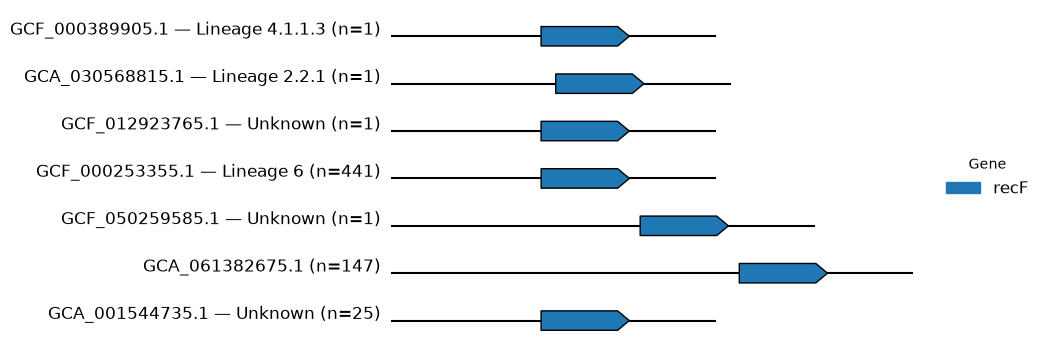

In [33]:
gbk_ordered = glob.glob('annot_test_repr/*.gbk')
struct_df = pd.read_csv('structure_results_test/structure_summary.csv')
fig, axes = lt.plot_locus_comparison(
    gbk_paths=gbk_ordered,
    metadata_df=final,
    structure_summary_df=struct_df,
    accession_col="AssemblyAccession",
    label_cols=['AssemblyAccession','sublineage'],      
    show_gene_labels=False,
)

## run workflow for RD900

In [45]:
reload(lt)
uphits, downhits = lt.blast_anchors('downstream_anchor.fa', 'upstream_anchor.fa', db)
lt.run_extraction('combined.fna', uphits, downhits, 'RD900_extracted.fa')

results = lt.annotate_genomes(
    inputs="RD900_extracted.fa",
    proteins="RD900MAF.faa",
    outdir="annot_new",
    min_id=0.40,
    min_cov=0.60
)

summary, representatives = lt.select_representatives(
    gbk_dir="annot_new",   
    fasta_file="RD900_extracted.fa",
    loci_fasta_dir="split_loci",
    out_dir = 'structure_results',
    annot_repr_dir="annot_repr",
    mash_threshold=0.001,
)

extracting locus from 10134 assemblies/contigs..
status
extracted          742
missing_anchor      24
anchors_too_far     22
strand_mismatch     11
anchor order among extracted genomes:
ref_order
down_first    742
wrote info to extraction_qc.csv
locus sequences written to RD900_extracted.fa
742 sequences to search
GCA_001544735.1: 5 CDS [AmbR(+), pknH1(-,frameshift_candidate), pknH2(-,partial), pknH1(-,frameshift_candidate), embR(-)] -> annot_new/GCA_001544735.1.gbk
GCA_001544775.1: 6 CDS [AmbR(+), pknH1(-), tbd2(-,frameshift_candidate), tbd2(-,frameshift_candidate), pknH2(-), embR(-)] -> annot_new/GCA_001544775.1.gbk
GCA_001544815.1: 6 CDS [AmbR(+), pknH1(-,frameshift_candidate), pknH1(-,frameshift_candidate), tbd2(-), pknH2(-), embR(-)] -> annot_new/GCA_001544815.1.gbk
GCA_001544855.1: 10 CDS [AmbR(+,frameshift_candidate), AmbR(+,frameshift_candidate), pknH1(-,frameshift_candidate), pknH1(-,frameshift_candidate), pknH1(-,frameshift_candidate), tbd2(-,frameshift_candidate), tbd2(-,fra

[warn] no metadata match for 'GCA_061376645.1' in column 'AssemblyAccession'; using accession as label
[warn] no metadata match for 'GCA_061386095.1' in column 'AssemblyAccession'; using accession as label
[warn] no metadata match for 'GCA_061388385.1' in column 'AssemblyAccession'; using accession as label
saved plot to locus_plot.png


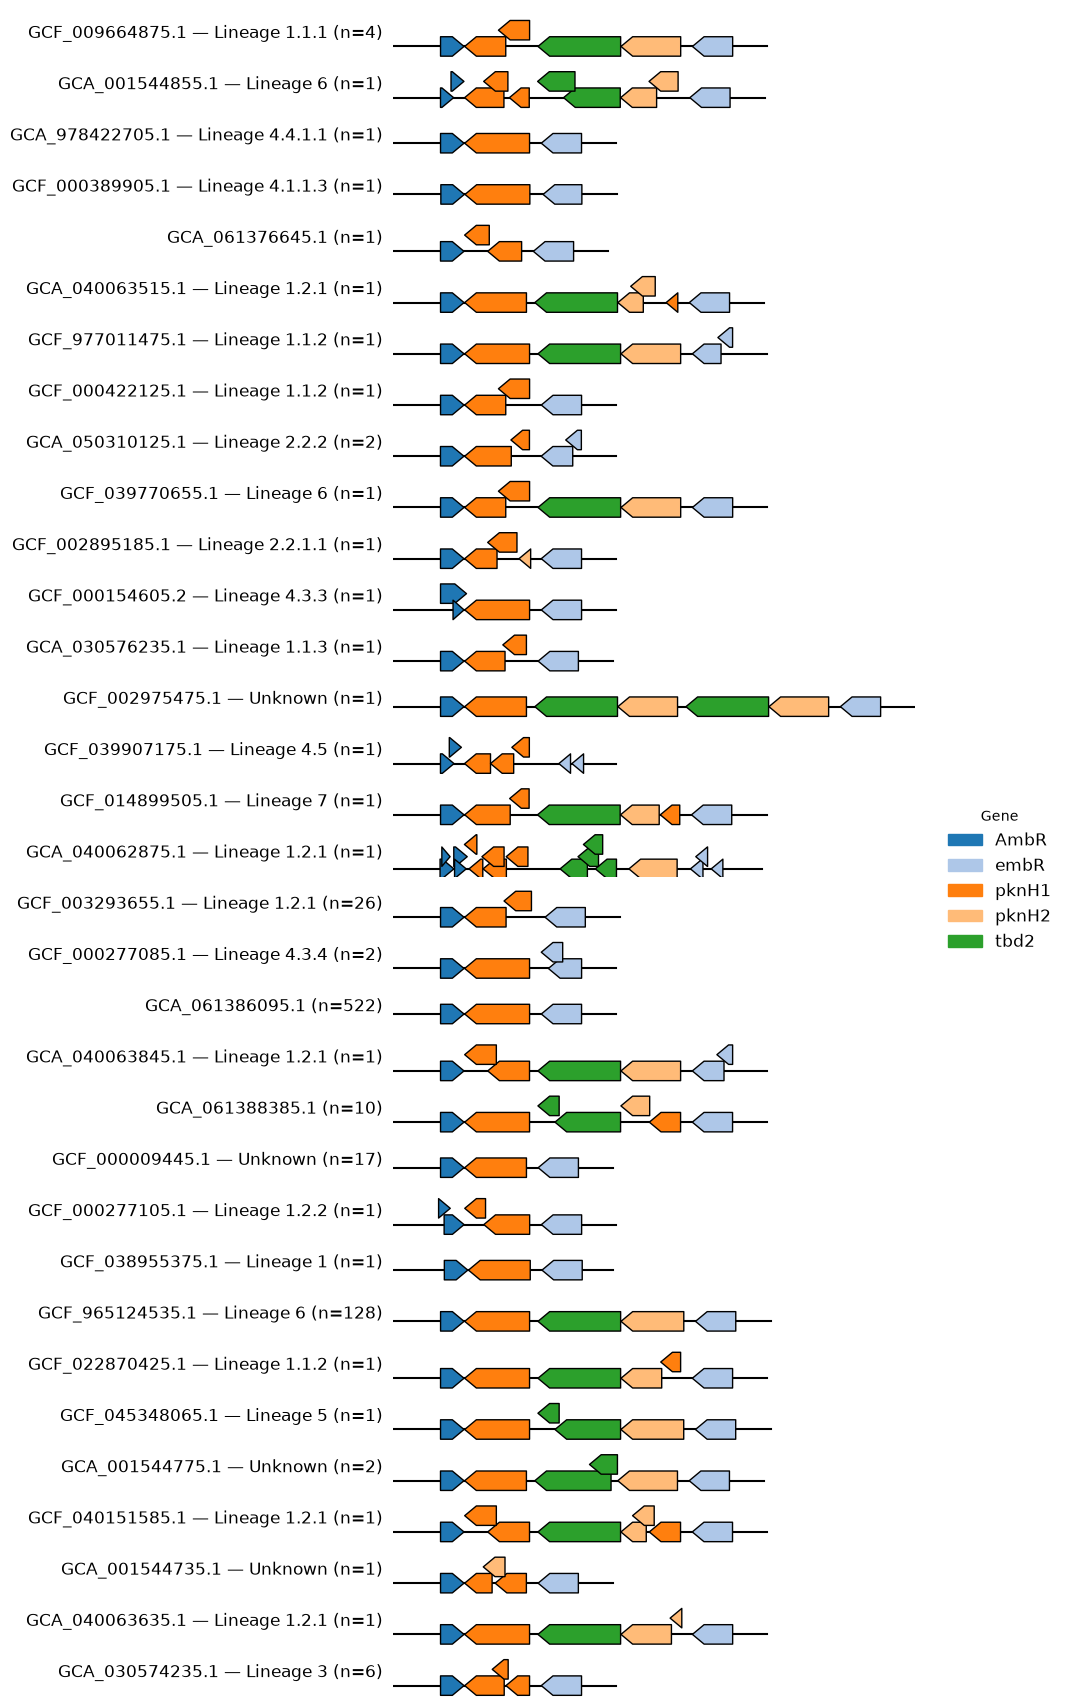

In [46]:
gbk_ordered = glob.glob('annot_repr/*.gbk') 
struct_df = pd.read_csv('structure_results/structure_summary.csv')

fig, axes = lt.plot_locus_comparison(
    gbk_paths=gbk_ordered,
    metadata_df=final,
    structure_summary_df=struct_df,
    accession_col="AssemblyAccession",
    label_cols=['AssemblyAccession','sublineage'],
    #indels_dict=indels_dict,
    hspace=0.05,
    row_height=0.55,       
    show_gene_labels=False,
)
fig.savefig('locus_plot.png', bbox_inches="tight")

## Extract protein sequences from annotations and compare them

In [ ]:
prot = 'pknH1'
reload(lt)
lt.extract_proteins('annot', prot, f'{prot}.faa')
lt.reduce_redundancy(f'{prot}.faa', f'{prot}_reduced.faa', 0.0005, k=6, threads=8)
lt.run_mafft(f'{prot}_reduced.faa', f'{prot}.aln', threads=12)

Saved rd900_alignment.png


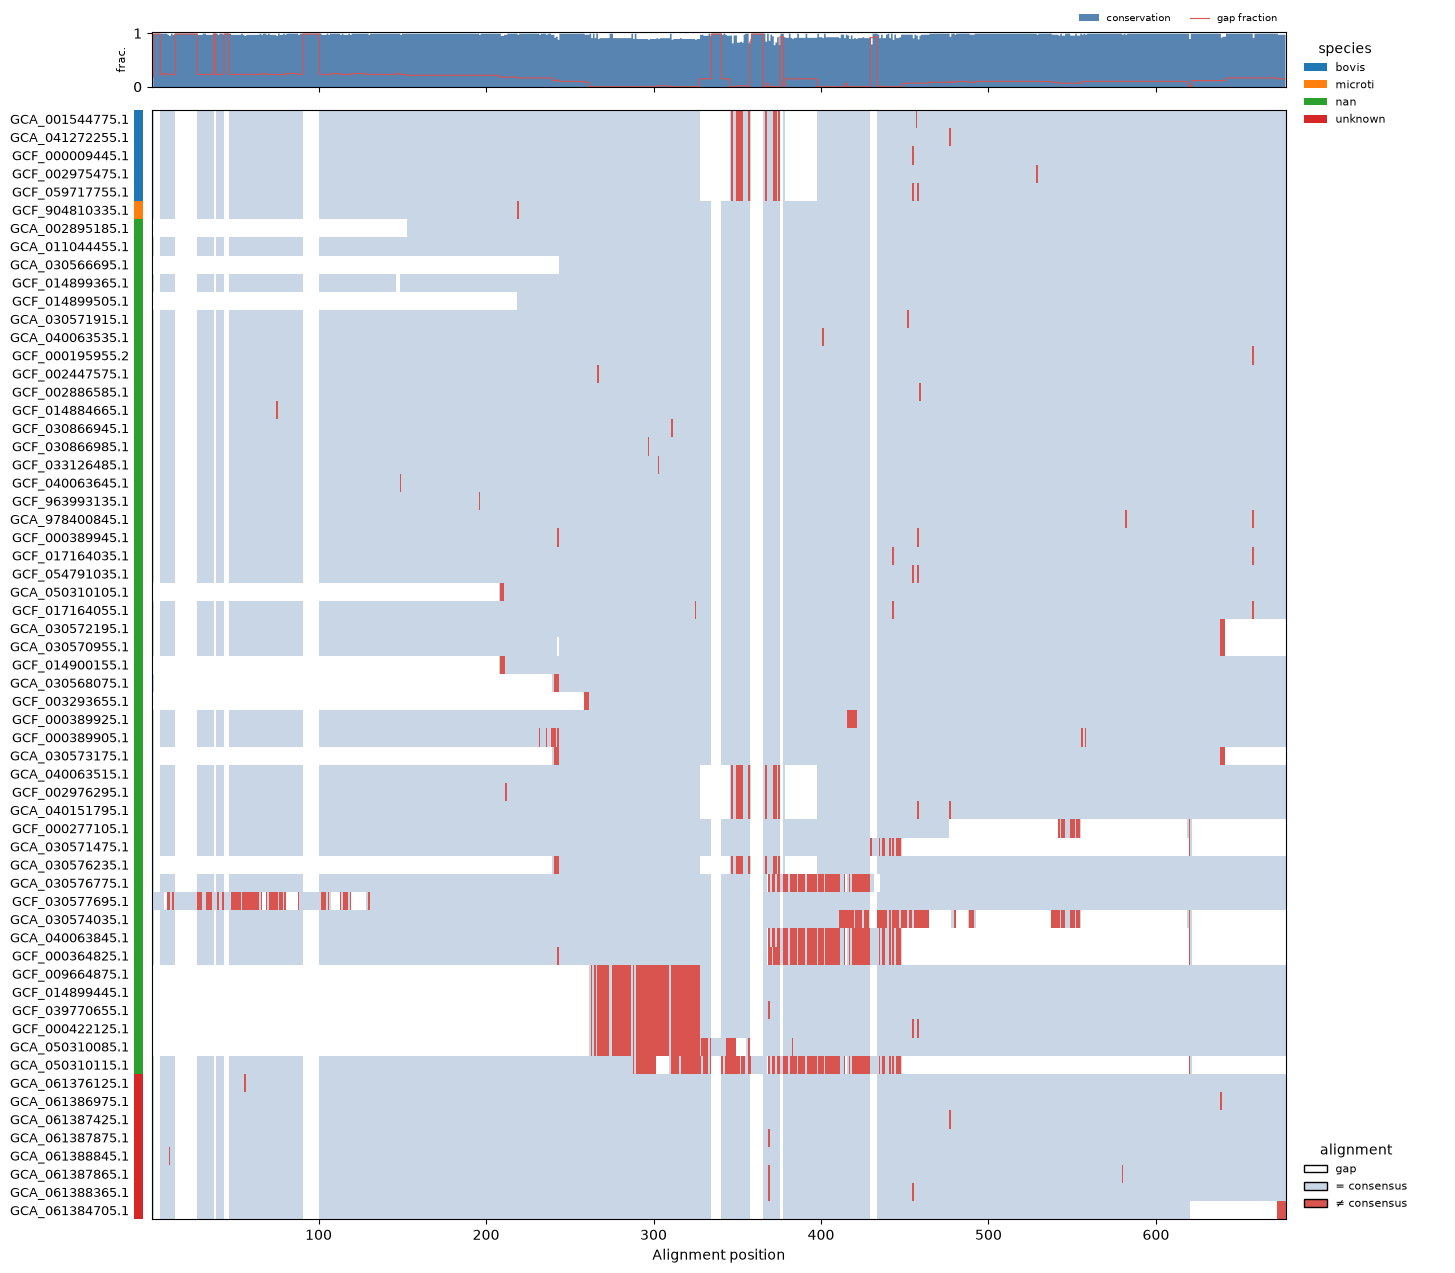

In [24]:
from plot_alignment import plot_alignment
fig, axes = plot_alignment(
    f'{prot}.aln', final,
    id_col="AssemblyAccession", 
    label_col="", # optional y-axis labels (default: the id)
    color_col="species",  
    mode="identity",    
    out="rd900_alignment.png",
)